# Step 0 - Parsing: which PDF parser?

A parser turns a file into text. Every later step (chunks, vectors, answers) only sees that text:
what the parser loses is lost for good.

We take **three real documents** from the corpus, run **five parsers** on them and look at what comes out.

In [1]:
import logging
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pymupdf

from src.config import load_config, project_path
from src.ingestion.parsing import MissingTextLayerError, build_pdf_parser

logging.disable(logging.WARNING)
pymupdf.set_messages(path=os.devnull)  # PyMuPDF prints one status line per file

RAW = project_path(load_config().paths.raw_documents_dir)
SHEET = RAW / "04_schede_impianto/SCH-IMP-01_scheda-impianto-fontechiara.pdf"
SCAN = RAW / "10_archivio_documentale/N-47-2019_contratto-noleggio-veicoli-47-2019.pdf"
BULLETIN = RAW / "10_archivio_documentale/BT-12_bollettino-tecnico-bt-12-vibrazioni-p7.pdf"
CONTRACT = RAW / "01_contratti/CTR-2024-017_Beta_manutenzione-pompe-sommergibili-p7-p9.pdf"
BACKENDS = ["pypdf", "pymupdf", "pdfplumber", "pymupdf4llm", "docling"]

INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "font.size": 10}
)

In [2]:
def show_page(path: Path, page: int, top: float, bottom: float) -> None:
    """Show a horizontal band of a PDF page; top and bottom are fractions of the page height."""
    with pymupdf.open(path) as pdf:
        box = pdf[page].rect
        band = pymupdf.Rect(box.x0, box.height * top, box.x1, box.height * bottom)
        pixmap = pdf[page].get_pixmap(dpi=110, clip=band)
    image = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n)
    plt.figure(figsize=(9, 9 * pixmap.height / pixmap.width))
    plt.imshow(image, cmap="gray")
    plt.axis("off")
    plt.show()


def lines_around(text: str | None, anchor: str, count: int) -> str:
    """The line that contains the anchor and the lines after it."""
    if text is None:
        return "(nothing: this parser found no text in the file)"
    lines = text.splitlines()
    start = next(index for index, line in enumerate(lines) if anchor in line)
    return "\n".join(lines[start : start + count])

Load the five parsers and read the three documents with each of them. The cell takes a couple of minutes:
Docling loads its models and both OCR-capable parsers have to read a scanned page.

In [3]:
%%capture
parsers = {name: build_pdf_parser(name) for name in BACKENDS}


def read(backend: str, path: Path) -> str | None:
    """Text of a file, or None when the parser finds no text in it."""
    try:
        return parsers[backend].parse(path).text
    except MissingTextLayerError:
        return None


texts = {backend: {path: read(backend, path) for path in (SHEET, SCAN, BULLETIN)} for backend in BACKENDS}

## Example 1 - a table

The plant sheet says who maintains each machine and how fast they must arrive. This is the page:

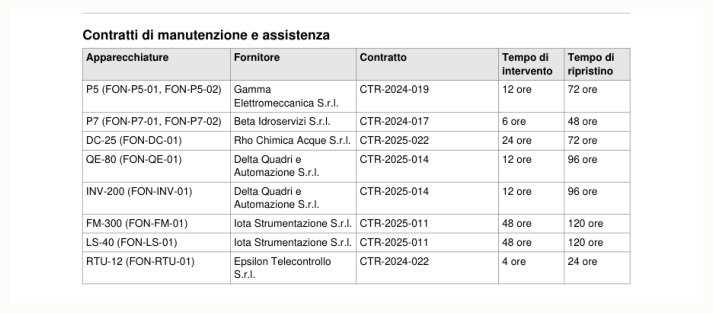

In [4]:
show_page(SHEET, page=1, top=0.07, bottom=0.37)

The row we care about is the second one: **P7 pumps, Beta Idroservizi, contract CTR-2024-017, 6 hours, 48 hours**.
Here is that row as two parsers return it.

In [5]:
for backend in ("pymupdf", "docling"):
    print(f"--- {backend}")
    print(lines_around(texts[backend][SHEET], "P7 (FON-P7-01", count=5 if backend == "pymupdf" else 1))
    print()

--- pymupdf
P7 (FON-P7-01, FON-P7-02)
Beta Idroservizi S.r.l.
CTR-2024-017
6 ore
48 ore

--- docling
| P7 (FON-P7-01, FON-P7-02) | Beta Idroservizi S.r.l.           | CTR-2024-017 | 6 ore                 | 48 ore                |



With `pymupdf` every cell is a line of its own. Once the text is cut into chunks, "6 ore" no longer knows
that it belongs to Beta and to the P7 pumps. `docling` keeps the row in one piece, as a Markdown table.

## Example 2 - a scanned contract

This contract from 2019 is a scan: the PDF holds a picture of the page, not text.

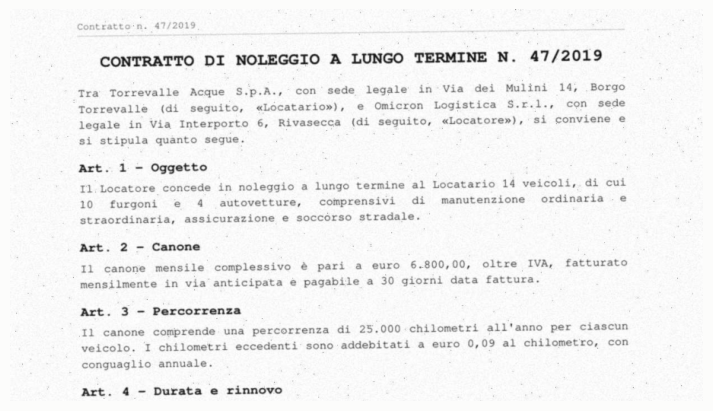

In [6]:
show_page(SCAN, page=0, top=0.05, bottom=0.45)

In [7]:
for backend in BACKENDS:
    text = texts[backend][SCAN]
    print(f"{backend:12s}", "no text at all" if text is None else f"{len(text)} characters read with OCR")

pypdf        no text at all
pymupdf      no text at all
pdfplumber   no text at all
pymupdf4llm  1787 characters read with OCR
docling      1651 characters read with OCR


For three parsers out of five this contract does not exist. The other two read it with OCR.
But OCR makes mistakes: look at Art. 3, which states the yearly mileage.

In [8]:
for backend in ("pymupdf4llm", "docling"):
    print(f"--- {backend}")
    print(lines_around(texts[backend][SCAN], "Percorrenza", count=3))
    print()

--- pymupdf4llm
Art. 3 - Percorrenza 

Il canone comprende una percorrenza di 25.000 chilometri all'anno per ciascun veicolo. I chilometri eccedenti sono addebitati a euro 0,09 al chilometro, con conguaglio annuale. 

--- docling
## Art. 3 - Percorrenza

I cn c,o c cocac c con cc  cn veicolo. I chilometri eccedenti sono addebitati a euro 0,09 al chilometro, con conguaglio annuale.



`docling` returned noise where the page says "25.000 chilometri": that fact is gone and nothing warned us.
A scanned page always needs a check after OCR.

## Example 3 - two columns

A technical bulletin laid out in two columns. A person reads the left column first, then the right one.

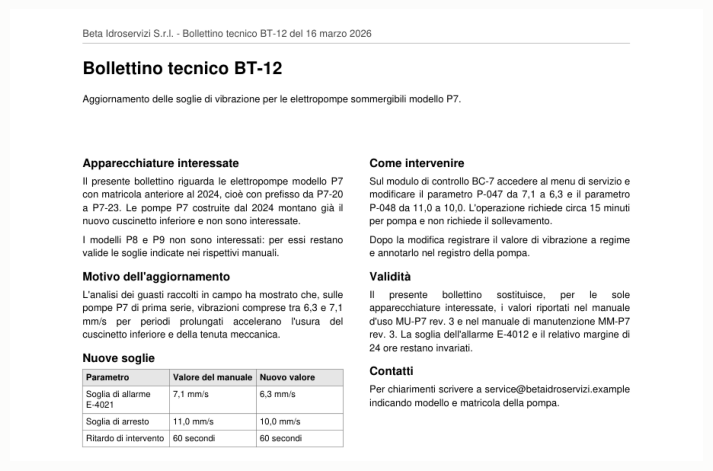

In [9]:
show_page(BULLETIN, page=0, top=0.04, bottom=0.5)

In [10]:
for backend in ("pdfplumber", "docling"):
    print(f"--- {backend}")
    print(lines_around(texts[backend][BULLETIN], "Nuove soglie", count=6))
    print()

--- pdfplumber
Nuove soglie
Contatti
Parametro Valore del manuale Nuovo valore
Per chiarimenti scrivere a service@betaidroservizi.example
Soglia di allarme 7,1 mm/s 6,3 mm/s
E-4021 indicando modello e matricola della pompa.

--- docling
## Nuove soglie

| Parametro                | Valore del manuale   | Nuovo valore   |
|--------------------------|----------------------|----------------|
| Soglia di allarme E-4021 | 7,1 mm/s             | 6,3 mm/s       |
| Soglia di arresto        | 11,0 mm/s            | 10,0 mm/s      |



`pdfplumber` reads straight across the page: the table on the left and the contact details on the right
end up in the same sentence. `docling` follows the columns.

## The whole picture

The same five checks for every parser.

In [11]:
def flat(text: str | None) -> str:
    """Text on a single line, empty when there is no text."""
    return " ".join((text or "").split())


def has_line(text: str | None, *parts: str) -> bool:
    """True when one line of the text contains every part."""
    return any(all(part in line for part in parts) for line in (text or "").splitlines())


def in_reading_order(text: str | None) -> bool:
    """True when the left column of the bulletin comes whole and before the right column."""
    line = flat(text)
    sentence = "con matricola anteriore al 2024, cioè con prefisso da P7-20 a P7-23"
    return sentence in line and 0 <= line.find("Nuove soglie") < line.find("Come intervenire")


CHECKS = {
    "reads the scanned contract": lambda b: texts[b][SCAN] is not None,
    "scan: the value 25.000 is right": lambda b: "25.000" in flat(texts[b][SCAN]),
    "keeps the table row together": lambda b: has_line(
        texts[b][SHEET], "CTR-2024-017", "Beta", "6 ore", "48 ore"
    ),
    "follows the two columns": lambda b: in_reading_order(texts[b][BULLETIN]),
    "marks the headings": lambda b: has_line(texts[b][BULLETIN], "#", "Nuove soglie"),
}
results = {label: [check(backend) for backend in BACKENDS] for label, check in CHECKS.items()}

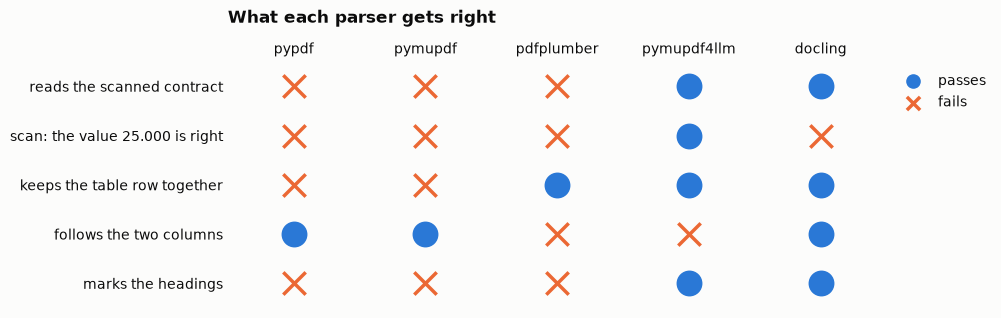

In [12]:
figure, axis = plt.subplots(figsize=(8.5, 3.2))
for row, passed in enumerate(results.values()):
    for column, ok in enumerate(passed):
        axis.scatter(
            column, row, s=260, marker="o" if ok else "x", color=BLUE if ok else ORANGE, linewidths=2.5
        )
axis.scatter([], [], s=90, marker="o", color=BLUE, label="passes")
axis.scatter([], [], s=90, marker="x", color=ORANGE, linewidths=2.5, label="fails")
axis.set_xticks(range(len(BACKENDS)), BACKENDS)
axis.set_yticks(range(len(results)), list(results))
axis.set_xlim(-0.5, len(BACKENDS) - 0.5)
axis.set_ylim(len(results) - 0.5, -0.5)
axis.xaxis.tick_top()
axis.tick_params(length=0, colors=INK)
axis.spines[:].set_visible(False)
axis.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
axis.set_title("What each parser gets right", loc="left", pad=28, fontweight="bold")
plt.show()

Quality has a price. The same four-page contract, read by each parser:

In [13]:
%%capture
seconds_per_page = {}
for backend in BACKENDS:
    start = time.perf_counter()
    pages = len(parsers[backend].parse(CONTRACT).pages)
    seconds_per_page[backend] = (time.perf_counter() - start) / pages

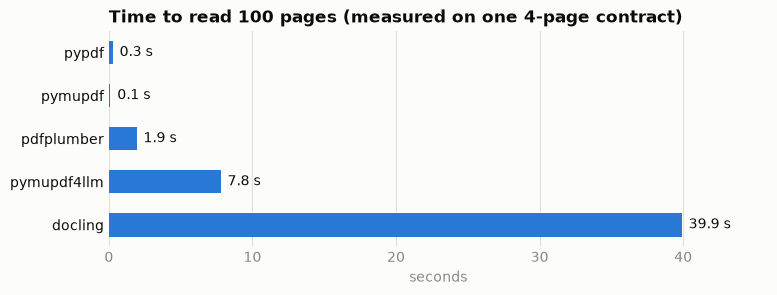

In [14]:
def duration(seconds: float) -> str:
    """A duration in the unit a person would use."""
    return f"{seconds:.1f} s" if seconds < 60 else f"{seconds / 60:.1f} min"


per_hundred = {backend: seconds_per_page[backend] * 100 for backend in BACKENDS}
figure, axis = plt.subplots(figsize=(8.5, 2.8))
bars = axis.barh(BACKENDS, list(per_hundred.values()), color=BLUE, height=0.55)
axis.bar_label(bars, labels=[duration(value) for value in per_hundred.values()], padding=5, color=INK)
axis.invert_yaxis()
axis.set_xlim(0, max(per_hundred.values()) * 1.15)
axis.set_xlabel("seconds", color=MUTED)
axis.tick_params(length=0, colors=INK)
axis.tick_params(axis="x", colors=MUTED)
axis.xaxis.grid(True, color=GRID, linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[:].set_visible(False)
axis.set_title("Time to read 100 pages (measured on one 4-page contract)", loc="left", fontweight="bold")
plt.show()

## What we take away

- **`pypdf`, `pymupdf`, `pdfplumber`** are fast, but they cannot read a scan and they break tables.
  On this corpus that means losing documents and facts before the pipeline even starts.
- **`pymupdf4llm`** reads everything and keeps tables and headings in about 8 seconds per 100 pages,
  but it puts the sections of the two-column page in the wrong order.
- **`docling`** is the only one that keeps tables, columns and headings. It is the slowest
  (about 40 seconds per 100 pages) and its OCR lost a number on the scanned contract.

**Choice: Docling**, set as `parsing.pdf_backend` in `src/conf/config.yaml`. Parsing runs once, offline,
and its result is saved: the time is paid once, while a broken table is paid at every question.

The command `python -m src.ingestion.parsing` parses the whole corpus (195 documents, about 5 minutes on a laptop CPU)
and saves the text in `data/artifacts/parsed`. The next notebooks start from there.

One thing stays open: scanned pages need a check after OCR, because a wrong line gives no warning.